In [ ]:
  # Step 1: Upgrade standard packaging tools and install core data/visualization libraries + spaCy
!pip install -q --upgrade pip setuptools wheel
!pip install -q spacy networkx matplotlib pandas seaborn

In [ ]:
!git clone https://github.com/jche253/Glaucoma_Med_Dataset.git

Cloning into 'Glaucoma_Med_Dataset'...
remote: Enumerating objects: 527, done.
remote: Counting objects: 100% (527/527), done.
remote: Compressing objects: 100% (519/519), done.
remote: Total 527 (delta 20), reused 487 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (527/527), 1.08 MiB | 2.83 MiB/s, done.
Resolving deltas: 100% (20/20), done.


Imports and configuration

In [ ]:
from pathlib import Path
from collections import Counter
import os
import re
import shutil
import sys
import subprocess
import importlib

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns
import spacy

from google.colab import files

# -----------------------------------------------------
# CONFIGURATION
# -----------------------------------------------------

NOTES_FOLDER = Path("Glaucoma_Med_Dataset/Deidentified_Notes")
OUTPUT_FOLDER = Path("output")

# Use 5 initially for easy visualization.
# Change to None later to process all notes.
MAX_NOTES = 6

# Create output folder
OUTPUT_FOLDER.mkdir(exist_ok=True)

print("Notes folder:", NOTES_FOLDER)
print("Output folder:", OUTPUT_FOLDER)

# -----------------------------------------------------
# AUTOMATIC MODEL INSTALLATION & RUNTIME FIX
# -----------------------------------------------------

# Ensure scispacy core library is installed first
try:
    importlib.import_module("scispacy")
except ImportError:
    print("Installing scispacy core...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scispacy==0.5.4", "--no-deps"])

# Helper to dynamically install source distributions of SciSpacy models
def ensure_scispacy_model(model_name, model_url):
    try:
        importlib.import_module(model_name)
    except ImportError:
        print(f"Installing missing model {model_name} directly from source...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", model_url])

ensure_scispacy_model(
    "en_core_sci_sm",
    "https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_core_sci_sm-0.5.4.tar.gz"
)
ensure_scispacy_model(
    "en_ner_bc5cdr_md",
    "https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_ner_bc5cdr_md-0.5.4.tar.gz"
)

def fix_spacy_model_config(model_name):
    try:
        # Dynamically import the installed package to find its actual directory path
        mod = importlib.import_module(model_name)
        model_dir = Path(mod.__file__).parent

        # Locate any config.cfg file inside the package folder
        configs = list(model_dir.glob("**/config.cfg"))
        if not configs:
            print(f"Could not find config.cfg inside package directory for {model_name}")
            return

        for config_path in configs:
            content = config_path.read_text()

            # Replace string True/False variants with raw config booleans
            new_content = content
            new_content = new_content.replace('include_static_vectors = "True"', 'include_static_vectors = true')
            new_content = new_content.replace("include_static_vectors = 'True'", "include_static_vectors = true")
            new_content = new_content.replace('include_static_vectors = "False"', 'include_static_vectors = false')
            new_content = new_content.replace("include_static_vectors = 'False'", "include_static_vectors = false")

            config_path.write_text(new_content)
            print(f"Successfully patched: {config_path}")

    except Exception as e:
        print(f"Error patching model {model_name}: {e}")

# Patch both scientific models on disk
fix_spacy_model_config("en_ner_bc5cdr_md")
fix_spacy_model_config("en_core_sci_sm")

# Load the models
print("\nLoading models...")
ner_model = spacy.load("en_ner_bc5cdr_md")
sci_model = spacy.load("en_core_sci_sm")
print("Biomedical NLP models loaded successfully!")

Notes folder: Glaucoma_Med_Dataset/Deidentified_Notes
Output folder: output
Installing missing model en_core_sci_sm directly from source...
Installing missing model en_ner_bc5cdr_md directly from source...


/usr/local/lib/python3.13/dist-packages/spacy/util.py:971: UserWarning: [W095] Model 'en_ner_bc5cdr_md' (0.5.4) was trained with spaCy v3.7.4 and may not be 100% compatible with the current version (3.8.18). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)
/usr/local/lib/python3.13/dist-packages/spacy/util.py:971: UserWarning: [W095] Model 'en_core_sci_sm' (0.5.4) was trained with spaCy v3.7.4 and may not be 100% compatible with the current version (3.8.18). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


Successfully patched: /usr/local/lib/python3.13/dist-packages/en_ner_bc5cdr_md/en_ner_bc5cdr_md-0.5.4/config.cfg
Successfully patched: /usr/local/lib/python3.13/dist-packages/en_core_sci_sm/en_core_sci_sm-0.5.4/config.cfg

Loading models...


/usr/local/lib/python3.13/dist-packages/spacy/language.py:2235: FutureWarning: Possible set union at position 6328
  deserializers["tokenizer"] = lambda p: self.tokenizer.from_disk(  # type: ignore[union-attr]
/usr/local/lib/python3.13/dist-packages/spacy/util.py:971: UserWarning: [W095] Model 'en_core_sci_sm' (0.5.4) was trained with spaCy v3.7.4 and may not be 100% compatible with the current version (3.8.18). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


Biomedical NLP models loaded successfully!


Load biomedical NLP models

In [ ]:
import subprocess
import importlib
import sys
from pathlib import Path

# Helper function to install SciSpaCy models if missing
def install_scispacy_model(model_url, model_name):
    try:
        importlib.import_module(model_name)
    except ImportError:
        print(f"Installing missing model {model_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", model_url])

# Install the required SciSpaCy models directly from official sources
install_scispacy_model(
    "https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_core_sci_sm-0.5.4-py3-none-any.whl",
    "en_core_sci_sm"
)
install_scispacy_model(
    "https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_ner_bc5cdr_md-0.5.4-py3-none-any.whl",
    "en_ner_bc5cdr_md"
)

import spacy

def fix_spacy_model_config(model_name):
    try:
        # Dynamically import the installed package to find its actual directory path
        mod = importlib.import_module(model_name)
        model_dir = Path(mod.__file__).parent

        # Locate any config.cfg file inside the package folder
        configs = list(model_dir.glob("**/config.cfg"))
        if not configs:
            print(f"Could not find config.cfg inside package directory for {model_name}")
            return

        for config_path in configs:
            content = config_path.read_text()

            # Replace string True/False variants with raw config booleans
            new_content = content
            new_content = new_content.replace('include_static_vectors = "True"', 'include_static_vectors = true')
            new_content = new_content.replace("include_static_vectors = 'True'", "include_static_vectors = true")
            new_content = new_content.replace('include_static_vectors = "False"', 'include_static_vectors = false')
            new_content = new_content.replace("include_static_vectors = 'False'", "include_static_vectors = false")

            config_path.write_text(new_content)
            print(f"Successfully patched: {config_path}")

    except Exception as e:
        print(f"Error patching model {model_name}: {e}")

# Patch both scientific models on disk
fix_spacy_model_config("en_ner_bc5cdr_md")
fix_spacy_model_config("en_core_sci_sm")

# Load the models
print("\nLoading models...")
ner_model = spacy.load("en_ner_bc5cdr_md")
sci_model = spacy.load("en_core_sci_sm")
print("Biomedical NLP models loaded successfully!")

Successfully patched: /usr/local/lib/python3.13/dist-packages/en_ner_bc5cdr_md/en_ner_bc5cdr_md-0.5.4/config.cfg
Successfully patched: /usr/local/lib/python3.13/dist-packages/en_core_sci_sm/en_core_sci_sm-0.5.4/config.cfg

Loading models...
Biomedical NLP models loaded successfully!


Complete functions

In [ ]:
def clean_entity(text):
    """
    Clean an entity name to avoid duplicate nodes caused by
    capitalization, punctuation, or multiple spaces.
    """
    text = text.lower().strip()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"^[^a-z0-9]+|[^a-z0-9]+$", "", text)
    return text


def is_valid_entity(text):
    """
    Ignore empty, masked, or extremely short entities.
    """
    if not text:
        return False

    if len(text) < 2:
        return False

    if set(text) == {"*"}:
        return False

    return True


def get_sentences(text):
    """
    Split a clinical note into sentences.
    """
    document = sci_model(text)

    sentences = [
        sentence.text.strip()
        for sentence in document.sents
        if sentence.text.strip()
    ]

    if not sentences:
        sentences = [text]

    return sentences


def extract_entities(text):
    """
    Extract disease/condition and chemical/drug entities.

    The model labels:
    DISEASE  -> condition or symptom node
    CHEMICAL -> medication or treatment node
    """
    document = ner_model(text)

    diseases = set()
    drugs = set()

    for entity in document.ents:
        entity_text = clean_entity(entity.text)

        if not is_valid_entity(entity_text):
            continue

        if entity.label_ == "DISEASE":
            diseases.add(entity_text)

        elif entity.label_ == "CHEMICAL":
            drugs.add(entity_text)

    return diseases, drugs


def build_patient_knowledge_graph(patient_id, note_text):
    """
    Construct graph for one patient.

    Node types:
    - patient
    - condition
    - drug

    Relationships:
    Patient -> has_symptom -> Condition
    Condition -> treated_with -> Drug

    The condition-drug relation is created when both appear
    in the same sentence, matching the paper's basic rule.
    """
    graph = nx.DiGraph()

    patient_node = f"PATIENT::{patient_id}"

    graph.add_node(
        patient_node,
        node_type="patient",
        label=patient_id
    )

    # Extract all entities from entire note
    all_diseases, all_drugs = extract_entities(note_text)

    # Add patient -> condition edges
    for disease in all_diseases:
        disease_node = f"CONDITION::{disease}"

        graph.add_node(
            disease_node,
            node_type="condition",
            label=disease
        )

        graph.add_edge(
            patient_node,
            disease_node,
            relation="has_symptom"
        )

    # Add drug nodes
    for drug in all_drugs:
        drug_node = f"DRUG::{drug}"

        graph.add_node(
            drug_node,
            node_type="drug",
            label=drug
        )

    # Find relationships sentence by sentence
    sentences = get_sentences(note_text)

    for sentence in sentences:
        sentence_diseases, sentence_drugs = extract_entities(sentence)

        # Ensure disease nodes and patient-condition links exist
        for disease in sentence_diseases:
            disease_node = f"CONDITION::{disease}"

            graph.add_node(
                disease_node,
                node_type="condition",
                label=disease
            )

            graph.add_edge(
                patient_node,
                disease_node,
                relation="has_symptom"
            )

        # Ensure drug nodes exist
        for drug in sentence_drugs:
            drug_node = f"DRUG::{drug}"

            graph.add_node(
                drug_node,
                node_type="drug",
                label=drug
            )

        # Condition -> Drug relation
        # Created when they co-occur in same sentence.
        for disease in sentence_diseases:
            for drug in sentence_drugs:
                disease_node = f"CONDITION::{disease}"
                drug_node = f"DRUG::{drug}"

                graph.add_edge(
                    disease_node,
                    drug_node,
                    relation="treated_with"
                )

    return graph, all_diseases, all_drugs


def calculate_graph_metrics(graph):
    """
    Calculate graph measures used in the paper.
    """
    total_nodes = graph.number_of_nodes()
    total_edges = graph.number_of_edges()

    if total_nodes == 0:
        return {
            "Total Nodes": 0,
            "Total Edges": 0,
            "Average Degree": 0,
            "Density": 0,
            "Average Clustering Coefficient": 0,
            "Average Shortest Path Length": 0,
            "Weakly Connected Components": 0
        }

    # Average degree = sum of node degrees / total nodes
    average_degree = (
        sum(dict(graph.degree()).values()) / total_nodes
    )

    # Convert directed graph to undirected for density,
    # clustering, and connected-component calculations.
    undirected_graph = graph.to_undirected()

    density = nx.density(undirected_graph)

    average_clustering = nx.average_clustering(
        undirected_graph
    )

    connected_components = list(
        nx.connected_components(undirected_graph)
    )

    component_count = len(connected_components)

    # Average shortest path only works for connected graphs.
    # Therefore, calculate it on the largest connected component.
    largest_component = max(
        connected_components,
        key=len
    )

    if len(largest_component) > 1:
        largest_subgraph = undirected_graph.subgraph(
            largest_component
        )

        average_shortest_path = nx.average_shortest_path_length(
            largest_subgraph
        )
    else:
        average_shortest_path = 0

    return {
        "Total Nodes": total_nodes,
        "Total Edges": total_edges,
        "Average Degree": round(average_degree, 4),
        "Density": round(density, 4),
        "Average Clustering Coefficient": round(
            average_clustering, 4
        ),
        "Average Shortest Path Length": round(
            average_shortest_path, 4
        ),
        "Weakly Connected Components": component_count
    }


def draw_knowledge_graph(graph, title, save_path):
    """
    Draw and save patient-centric knowledge graph.

    Red    -> Patient
    Orange -> Condition / symptom
    Green  -> Drug / treatment
    """
    if graph.number_of_nodes() == 0:
        print("Graph is empty. Cannot draw graph.")
        return

    plt.figure(figsize=(18, 12))

    positions = nx.spring_layout(
        graph,
        seed=42,
        k=1.2
    )

    node_colors = []

    for node in graph.nodes:
        node_type = graph.nodes[node]["node_type"]

        if node_type == "patient":
            node_colors.append("red")
        elif node_type == "condition":
            node_colors.append("orange")
        else:
            node_colors.append("green")

    nx.draw_networkx_nodes(
        graph,
        positions,
        node_size=1400,
        node_color=node_colors,
        alpha=0.9
    )

    nx.draw_networkx_edges(
        graph,
        positions,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=18,
        edge_color="gray",
        width=1.5
    )

    node_labels = {
        node: graph.nodes[node]["label"]
        for node in graph.nodes
    }

    nx.draw_networkx_labels(
        graph,
        positions,
        labels=node_labels,
        font_size=8
    )

    edge_labels = {
        (source, target): data["relation"]
        for source, target, data in graph.edges(data=True)
    }

    nx.draw_networkx_edge_labels(
        graph,
        positions,
        edge_labels=edge_labels,
        font_size=7,
        font_color="blue"
    )

    plt.title(title, fontsize=16)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


def create_association_heatmap(graph, save_path):
    """
    Create and save a condition-treatment association heatmap.

    Each cell contains number of extracted
    Condition -> Drug relationships.
    """
    association_counter = Counter()

    for source, target, data in graph.edges(data=True):
        if data["relation"] == "treated_with":
            condition = graph.nodes[source]["label"]
            drug = graph.nodes[target]["label"]

            association_counter[(condition, drug)] += 1

    if not association_counter:
        print("No condition-drug associations found.")
        return None

    rows = []

    for (condition, drug), count in association_counter.items():
        rows.append({
            "Condition": condition,
            "Drug": drug,
            "Association Count": count
        })

    association_dataframe = pd.DataFrame(rows)

    heatmap_data = association_dataframe.pivot_table(
        index="Condition",
        columns="Drug",
        values="Association Count",
        aggfunc="sum",
        fill_value=0
    )

    # Sort rows and columns by total association count
    heatmap_data = heatmap_data.loc[
        heatmap_data.sum(axis=1).sort_values(
            ascending=False
        ).index,
        heatmap_data.sum(axis=0).sort_values(
            ascending=False
        ).index
    ]

    plt.figure(
        figsize=(
            max(12, len(heatmap_data.columns) * 1.2),
            max(6, len(heatmap_data.index) * 0.7)
        )
    )

    sns.heatmap(
        heatmap_data,
        cmap="YlGnBu",
        annot=True,
        fmt="g",
        linewidths=0.5,
        cbar_kws={
            "label": "Number of Condition-Drug Associations"
        }
    )

    plt.title("Condition-Treatment Association Heatmap")
    plt.xlabel("Drugs / Treatments")
    plt.ylabel("Conditions / Symptoms")
    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    return heatmap_data

 Process the dataset and create patient graphs

Total clinical notes found: 480
Clinical notes selected: 6
Processing 1/6: 01655bde5b.txt
Conditions extracted: 13
Drugs extracted: 8
Total nodes: 23
Total edges: 21


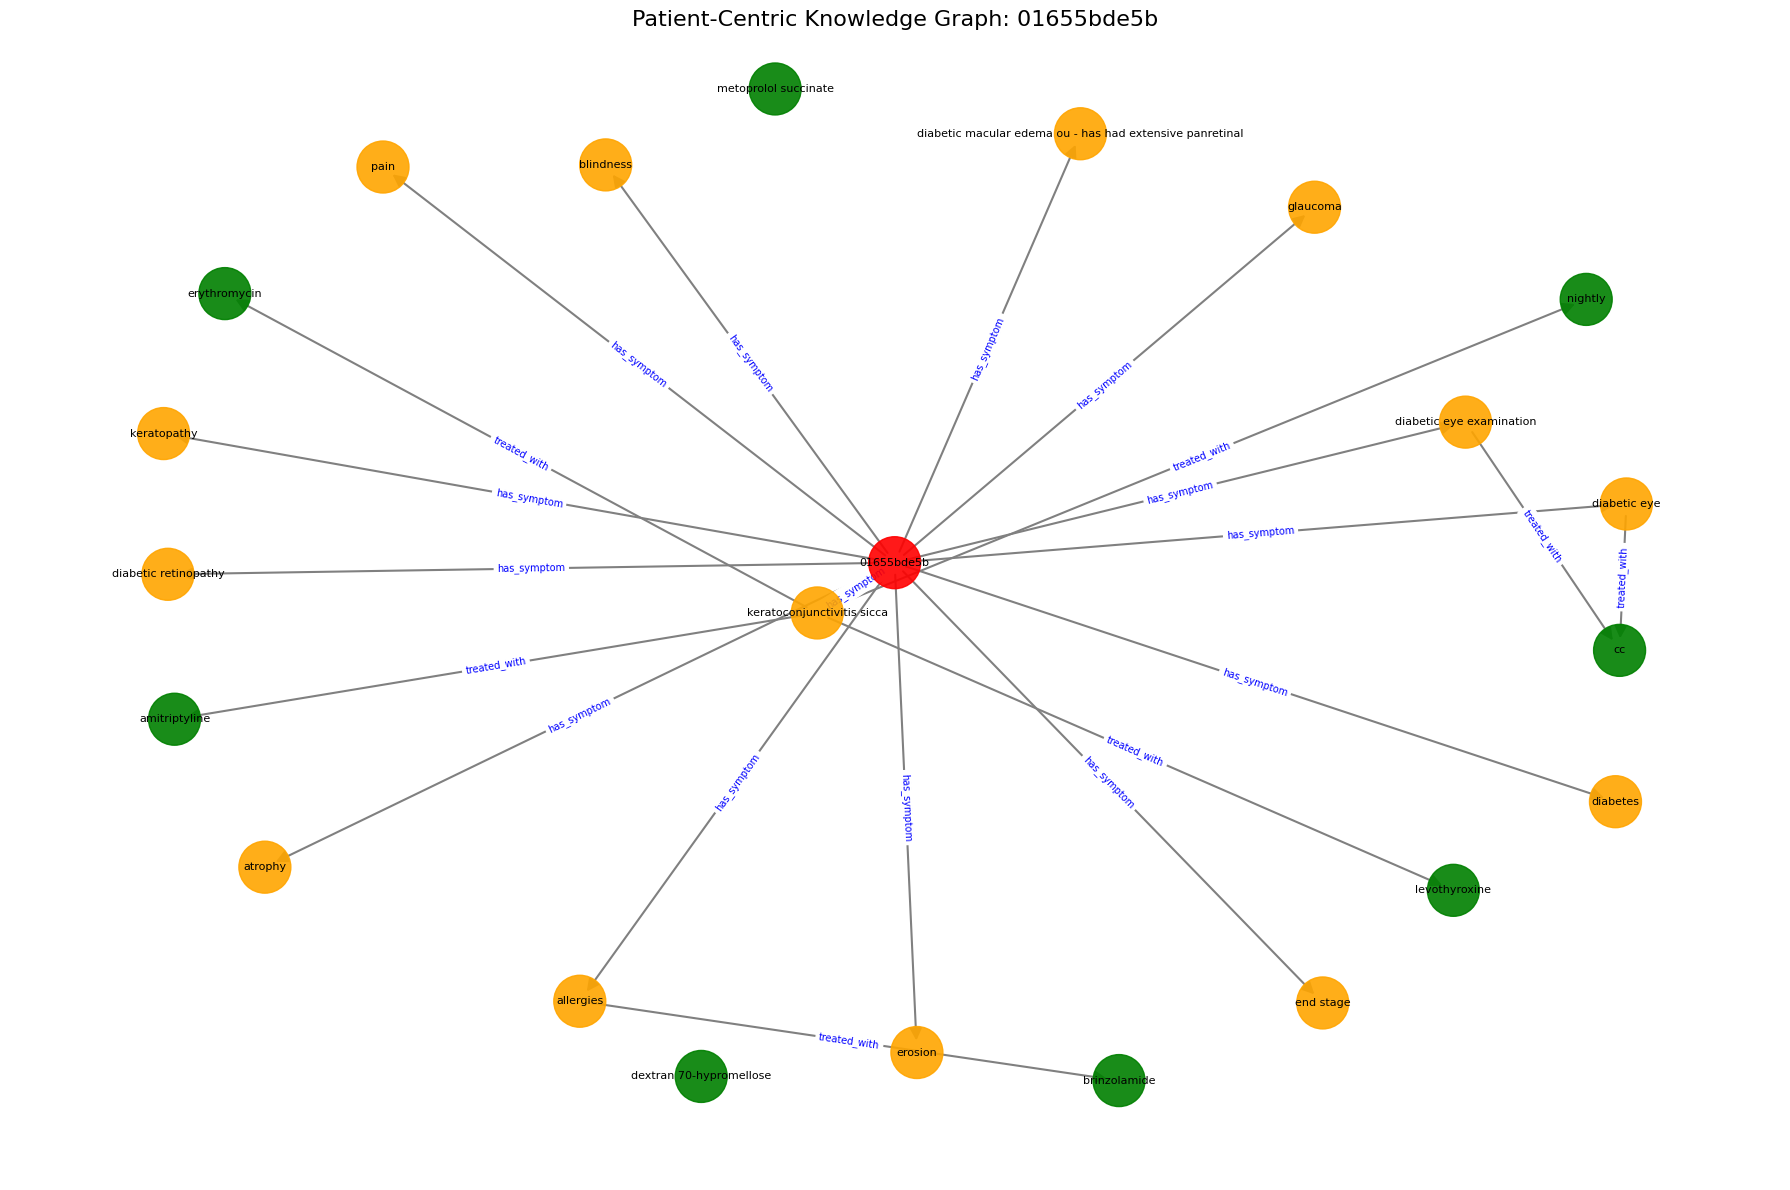

Processing 2/6: 01dcccc1a1.txt
Conditions extracted: 16
Drugs extracted: 14
Total nodes: 32
Total edges: 32


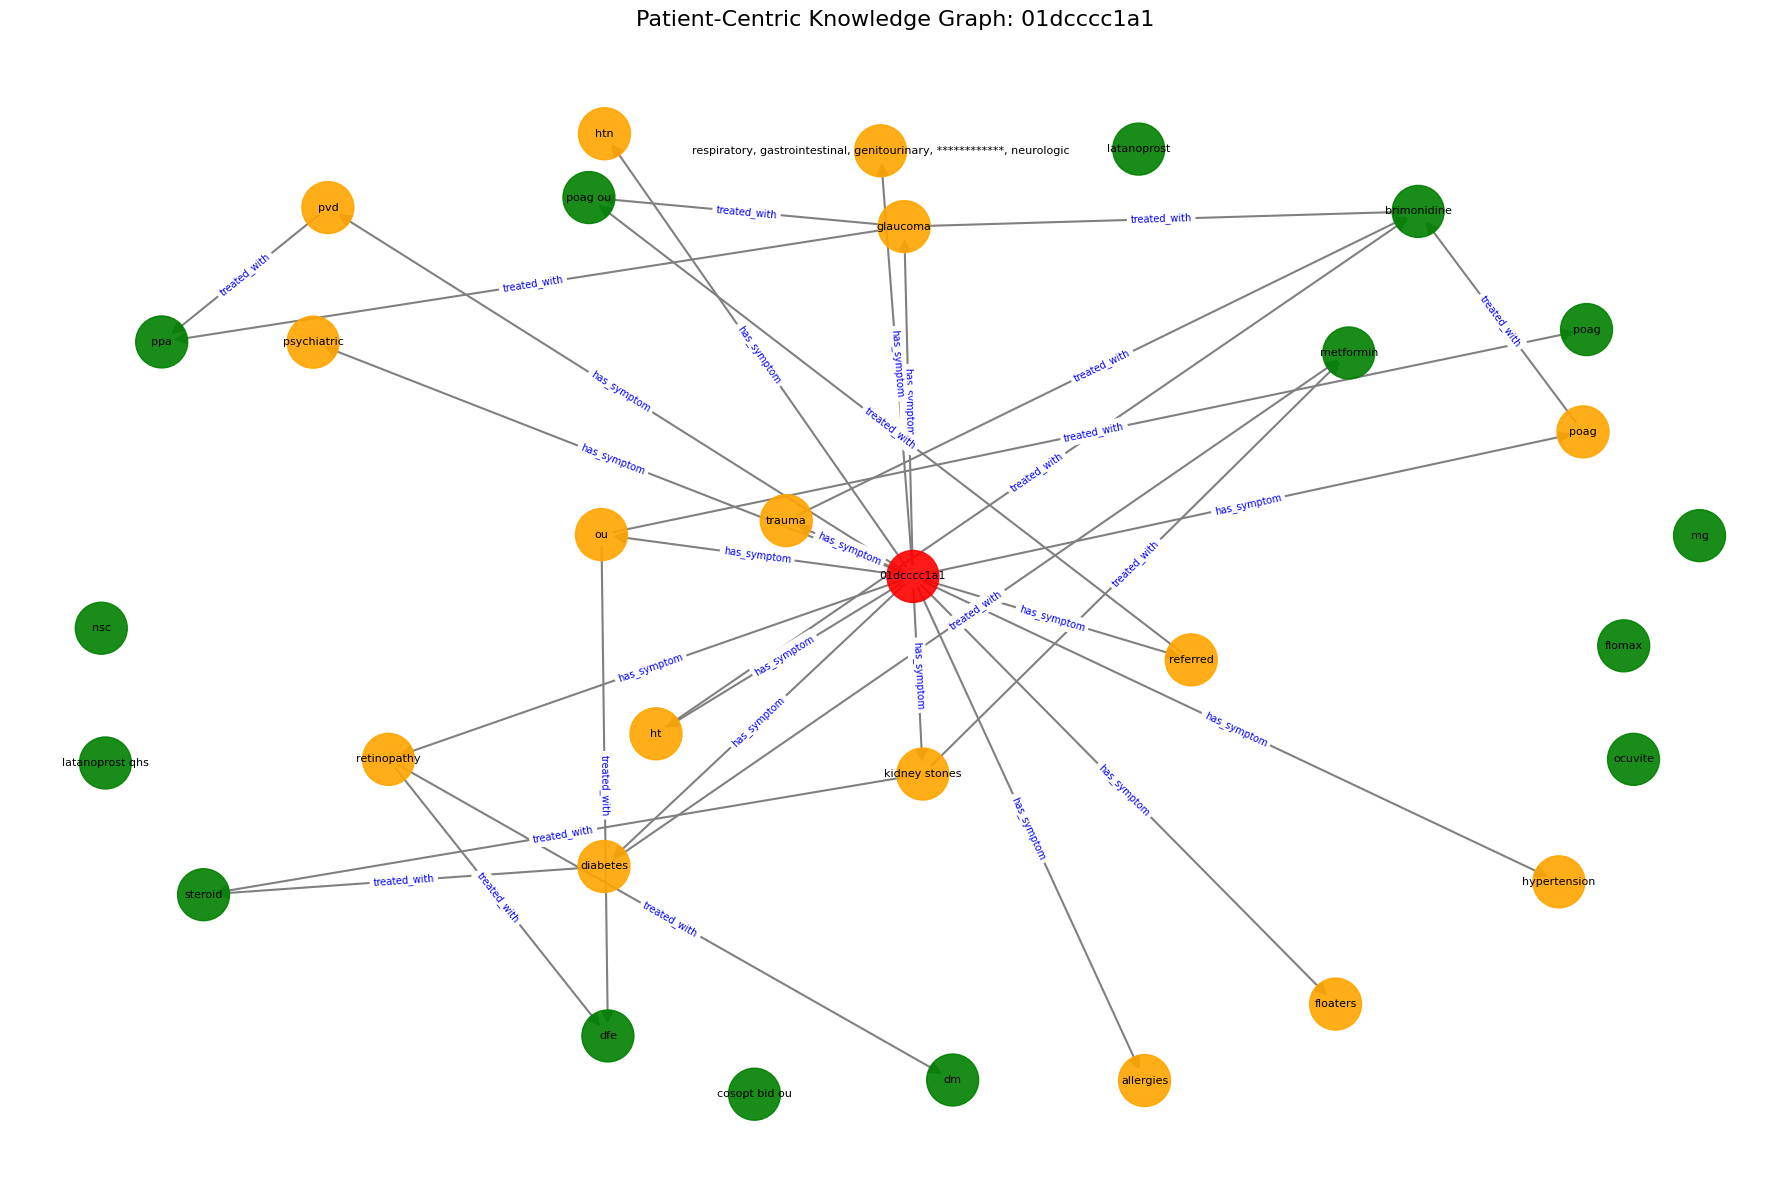

Processing 3/6: 0217483bd3.txt
Conditions extracted: 21
Drugs extracted: 19
Total nodes: 41
Total edges: 124


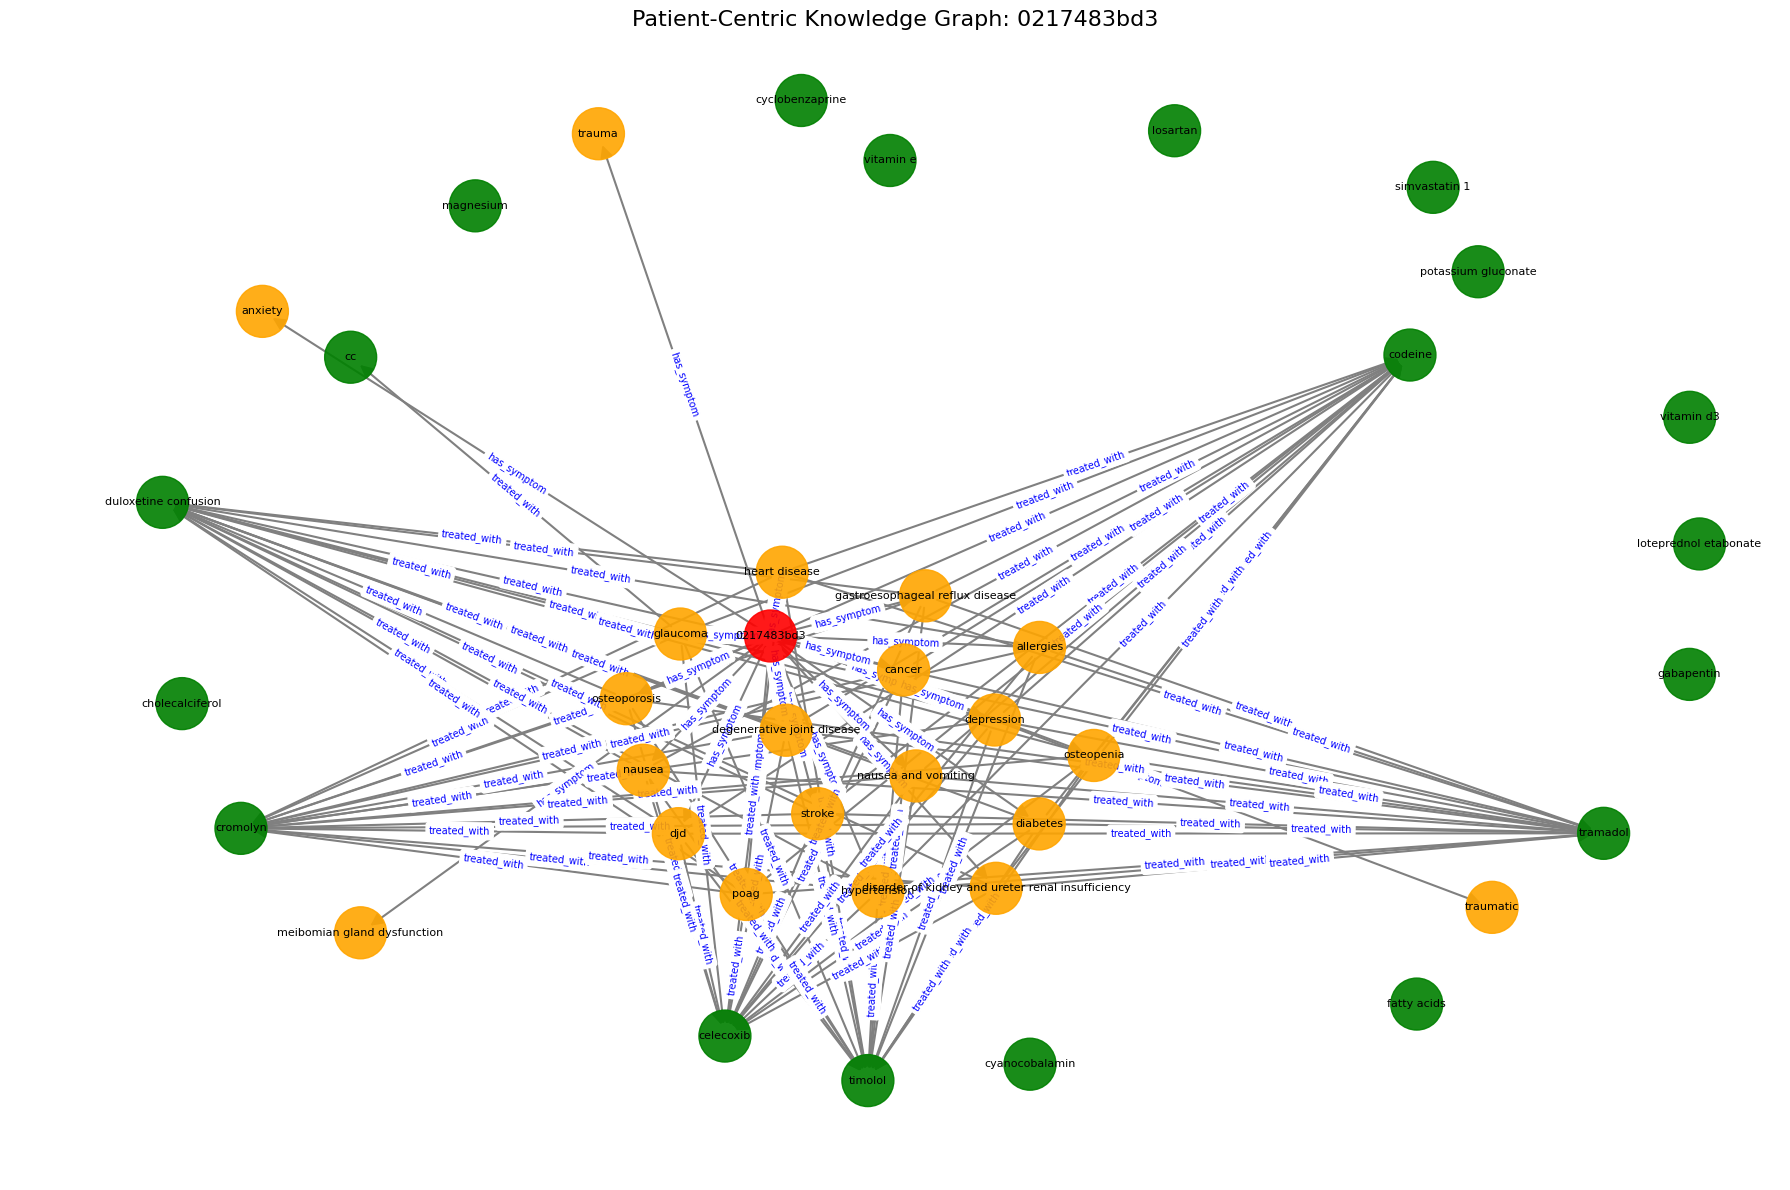

Processing 4/6: 025920c6c9.txt
Conditions extracted: 14
Drugs extracted: 13
Total nodes: 28
Total edges: 29


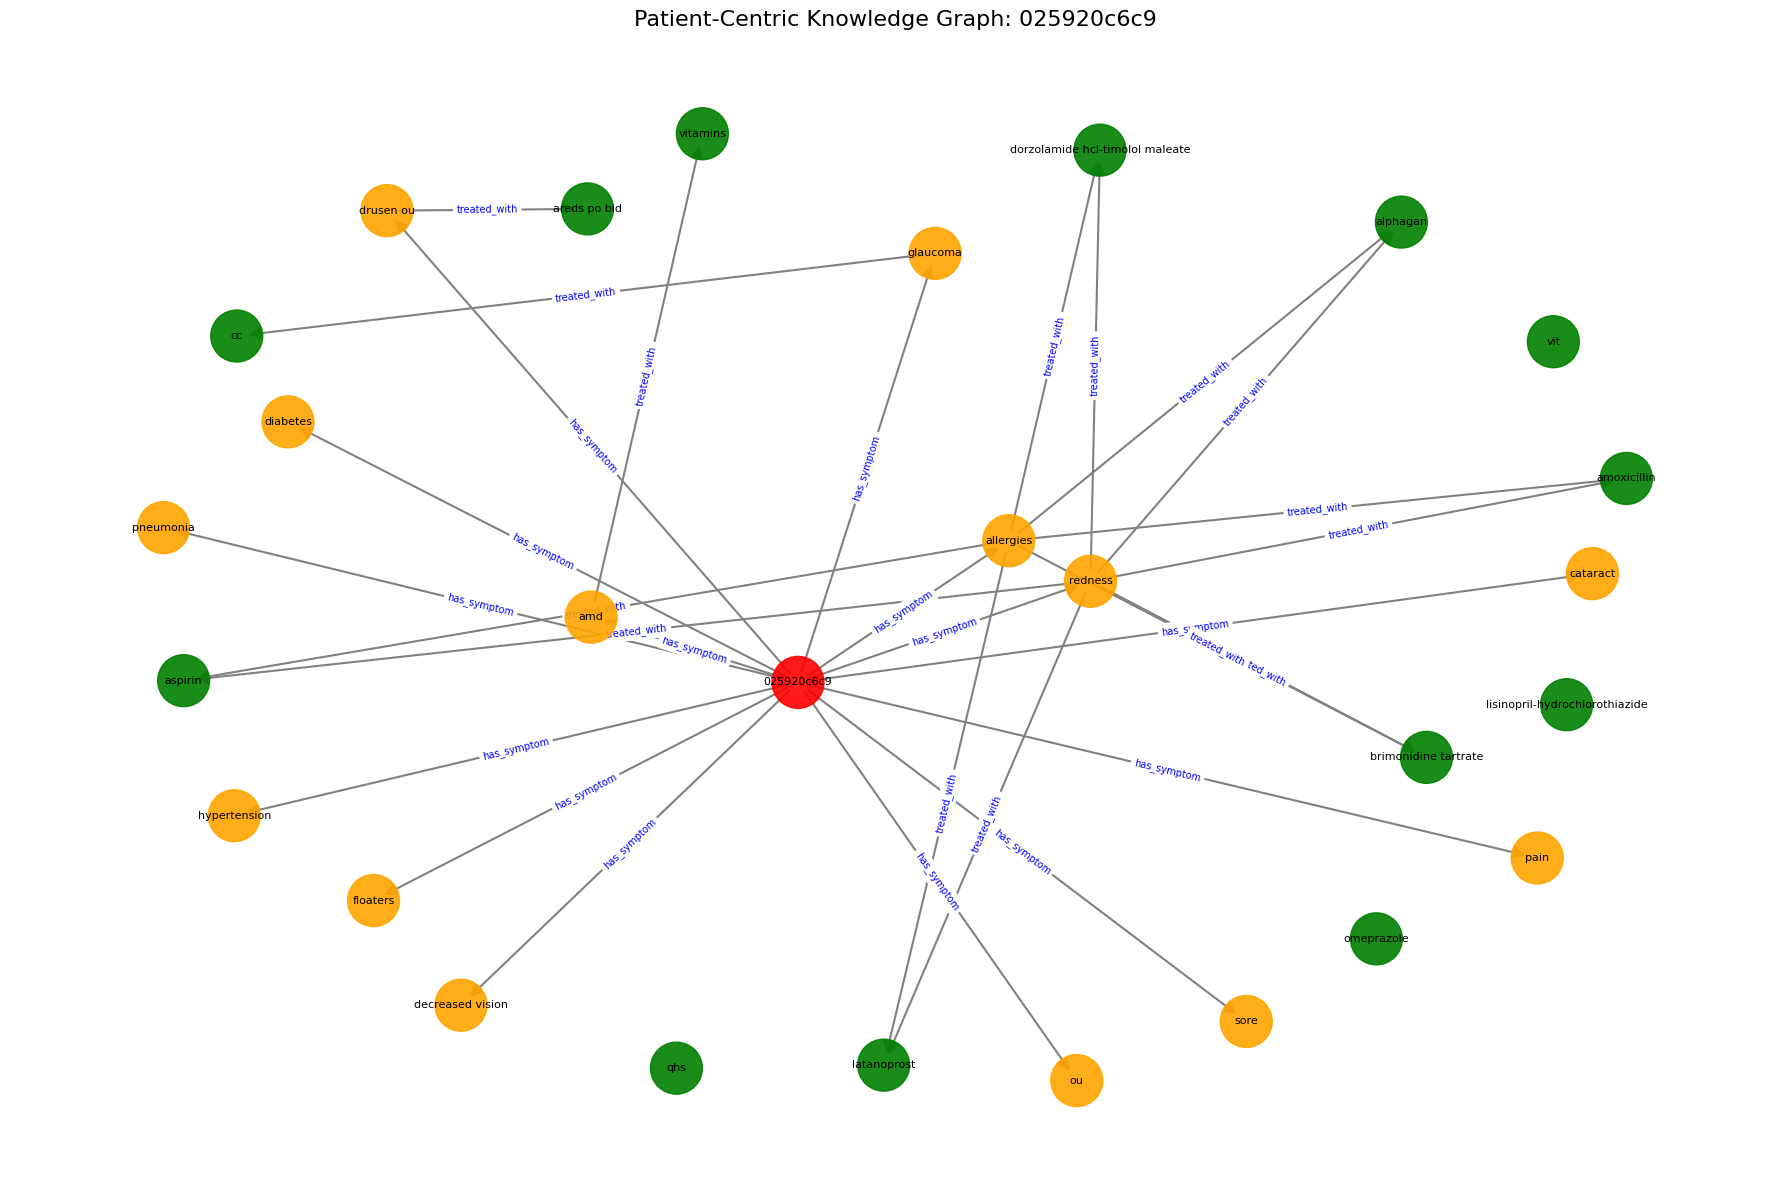

Processing 5/6: 0333bead9c.txt
Conditions extracted: 19
Drugs extracted: 13
Total nodes: 33
Total edges: 28


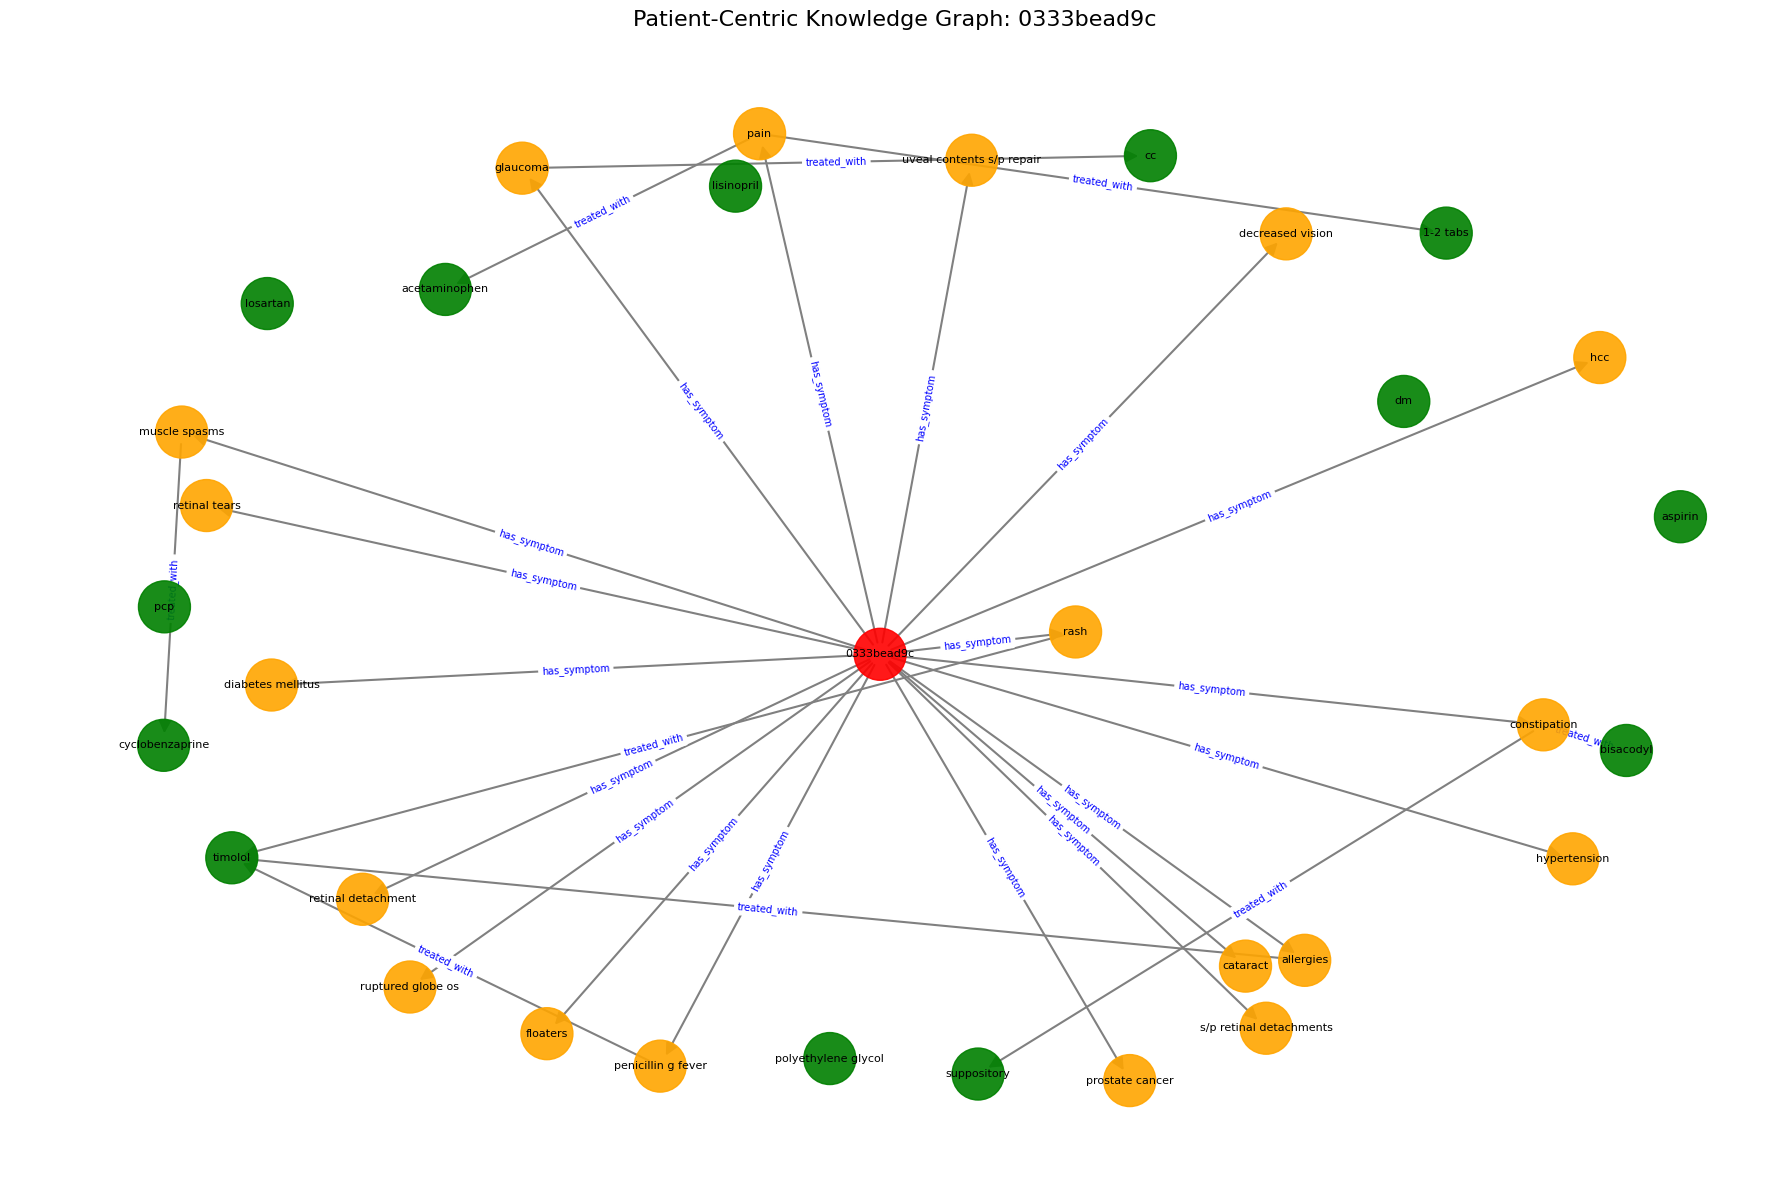

Processing 6/6: 04bd960ee3.txt
Conditions extracted: 36
Drugs extracted: 27
Total nodes: 64
Total edges: 221


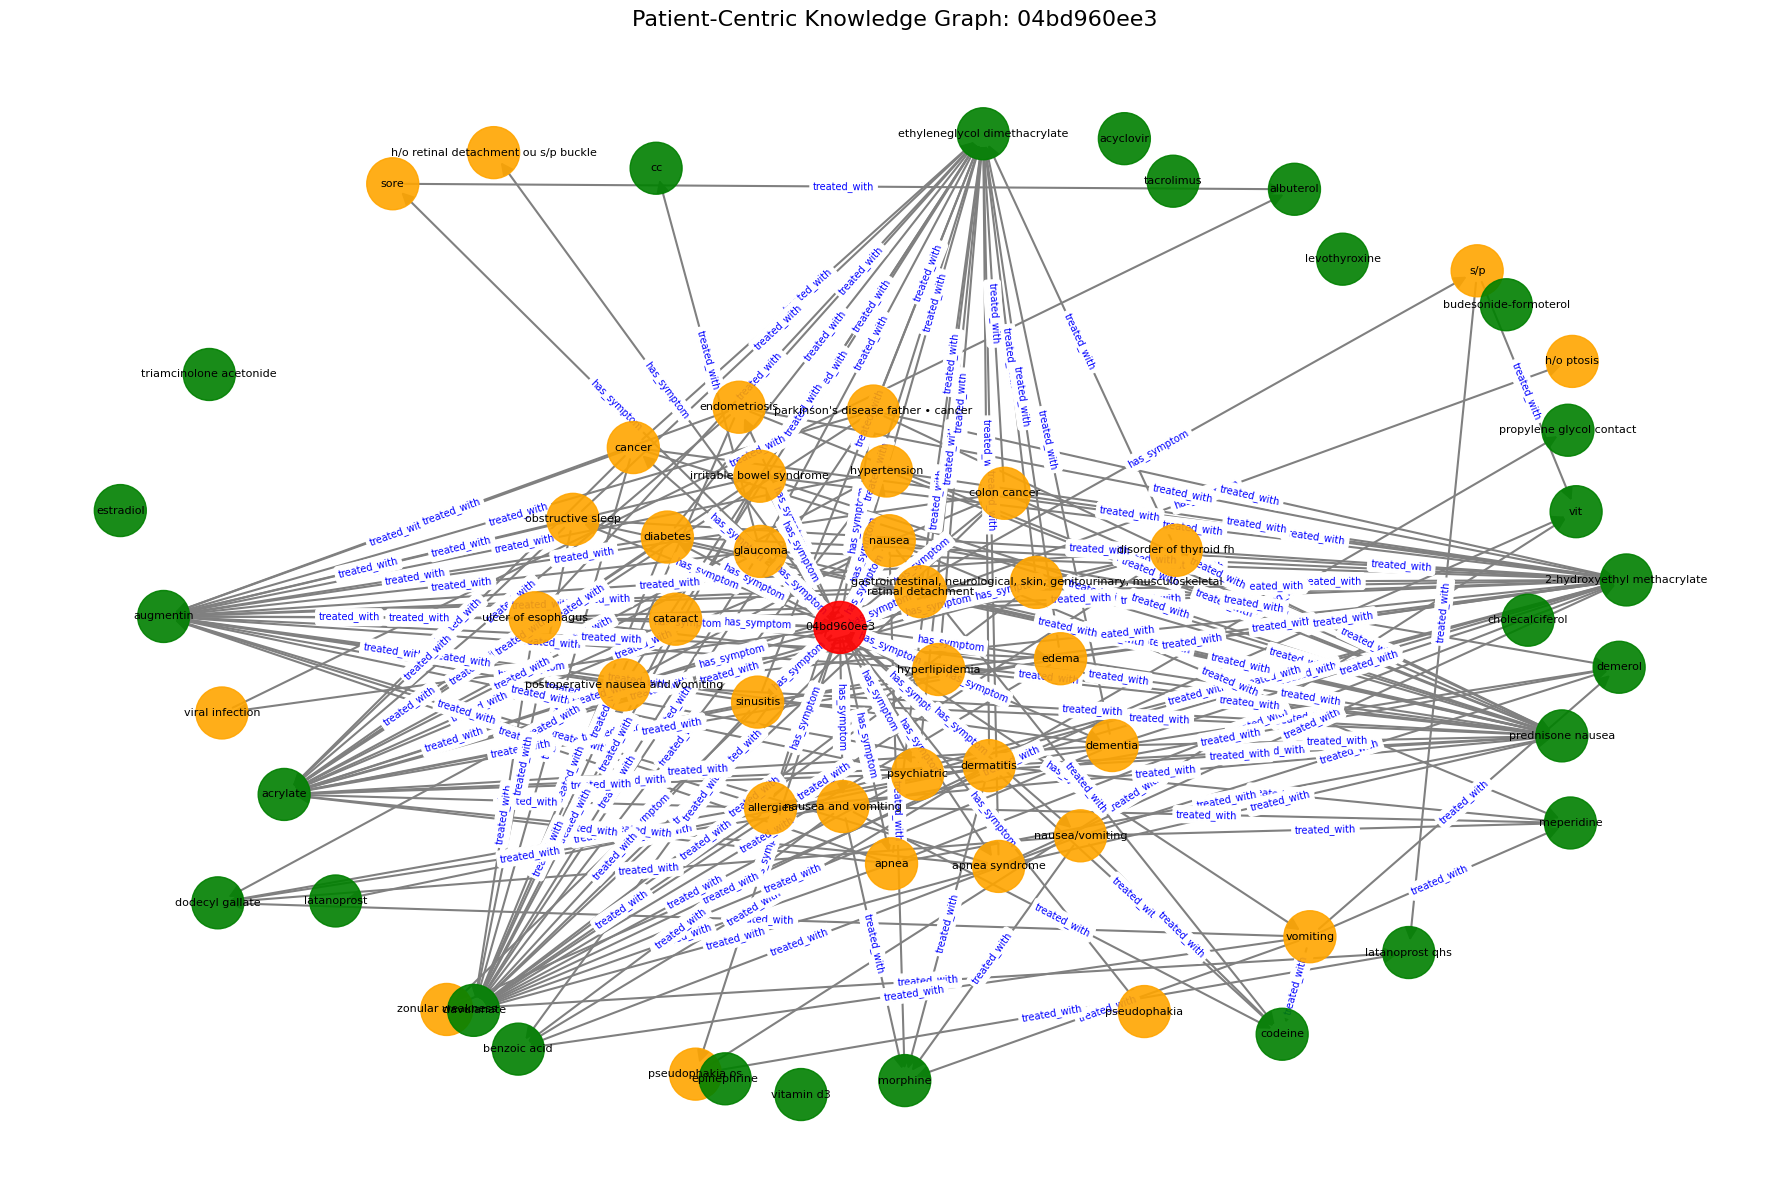


All selected patient notes processed successfully.


In [ ]:
if not NOTES_FOLDER.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {NOTES_FOLDER}"
    )

note_files = sorted(NOTES_FOLDER.glob("*.txt"))

if len(note_files) == 0:
    raise FileNotFoundError(
        "No clinical note .txt files found."
    )

print("Total clinical notes found:", len(note_files))

if MAX_NOTES is None:
    selected_files = note_files
else:
    selected_files = note_files[:MAX_NOTES]

print("Clinical notes selected:", len(selected_files))


combined_graph = nx.DiGraph()
all_patient_metrics = []

for index, note_file in enumerate(selected_files, start=1):
    patient_id = note_file.stem

    print("=" * 70)
    print(f"Processing {index}/{len(selected_files)}: {note_file.name}")

    with open(
        note_file,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as file:
        note_text = file.read()

    patient_graph, diseases, drugs = build_patient_knowledge_graph(
        patient_id,
        note_text
    )

    metrics = calculate_graph_metrics(patient_graph)

    print("Conditions extracted:", len(diseases))
    print("Drugs extracted:", len(drugs))
    print("Total nodes:", metrics["Total Nodes"])
    print("Total edges:", metrics["Total Edges"])

    patient_graph_file = OUTPUT_FOLDER / f"{patient_id}_graph.png"

    draw_knowledge_graph(
        patient_graph,
        f"Patient-Centric Knowledge Graph: {patient_id}",
        patient_graph_file
    )

    all_patient_metrics.append({
        "File": note_file.name,
        "Patient ID": patient_id,
        "Conditions Extracted": len(diseases),
        "Drugs Extracted": len(drugs),
        **metrics
    })

    combined_graph = nx.compose(
        combined_graph,
        patient_graph
    )

print("\nAll selected patient notes processed successfully.")

Combined graph, metrics, heatmap, and downloads

COMBINED KNOWLEDGE GRAPH
Total Nodes: 170
Total Edges: 449
Average Degree: 5.2824
Density: 0.0313
Average Clustering Coefficient: 0.0
Average Shortest Path Length: 3.3572
Weakly Connected Components: 31

Combined Graph Nodes: 170
Combined Graph Edges: 449

Patient metrics saved: output/patient_metrics.csv


,File,Patient ID,Conditions Extracted,Drugs Extracted,Total Nodes,Total Edges,Average Degree,Density,Average Clustering Coefficient,Average Shortest Path Length,Weakly Connected Components
0,01655bde5b.txt,01655bde5b,13,8,23,21,1.8261,0.0830,0.0,2.3524,3
1,01dcccc1a1.txt,01dcccc1a1,16,14,32,32,2.0000,0.0645,0.0,2.4133,8
2,0217483bd3.txt,0217483bd3,21,19,41,124,6.0488,0.1512,0.0,1.8030,13
3,025920c6c9.txt,025920c6c9,14,13,28,29,2.0714,0.0767,0.0,2.4493,5
4,0333bead9c.txt,0333bead9c,19,13,33,28,1.6970,0.0530,0.0,2.3818,7
5,04bd960ee3.txt,04bd960ee3,36,27,64,221,6.9062,0.1096,0.0,2.2370,10


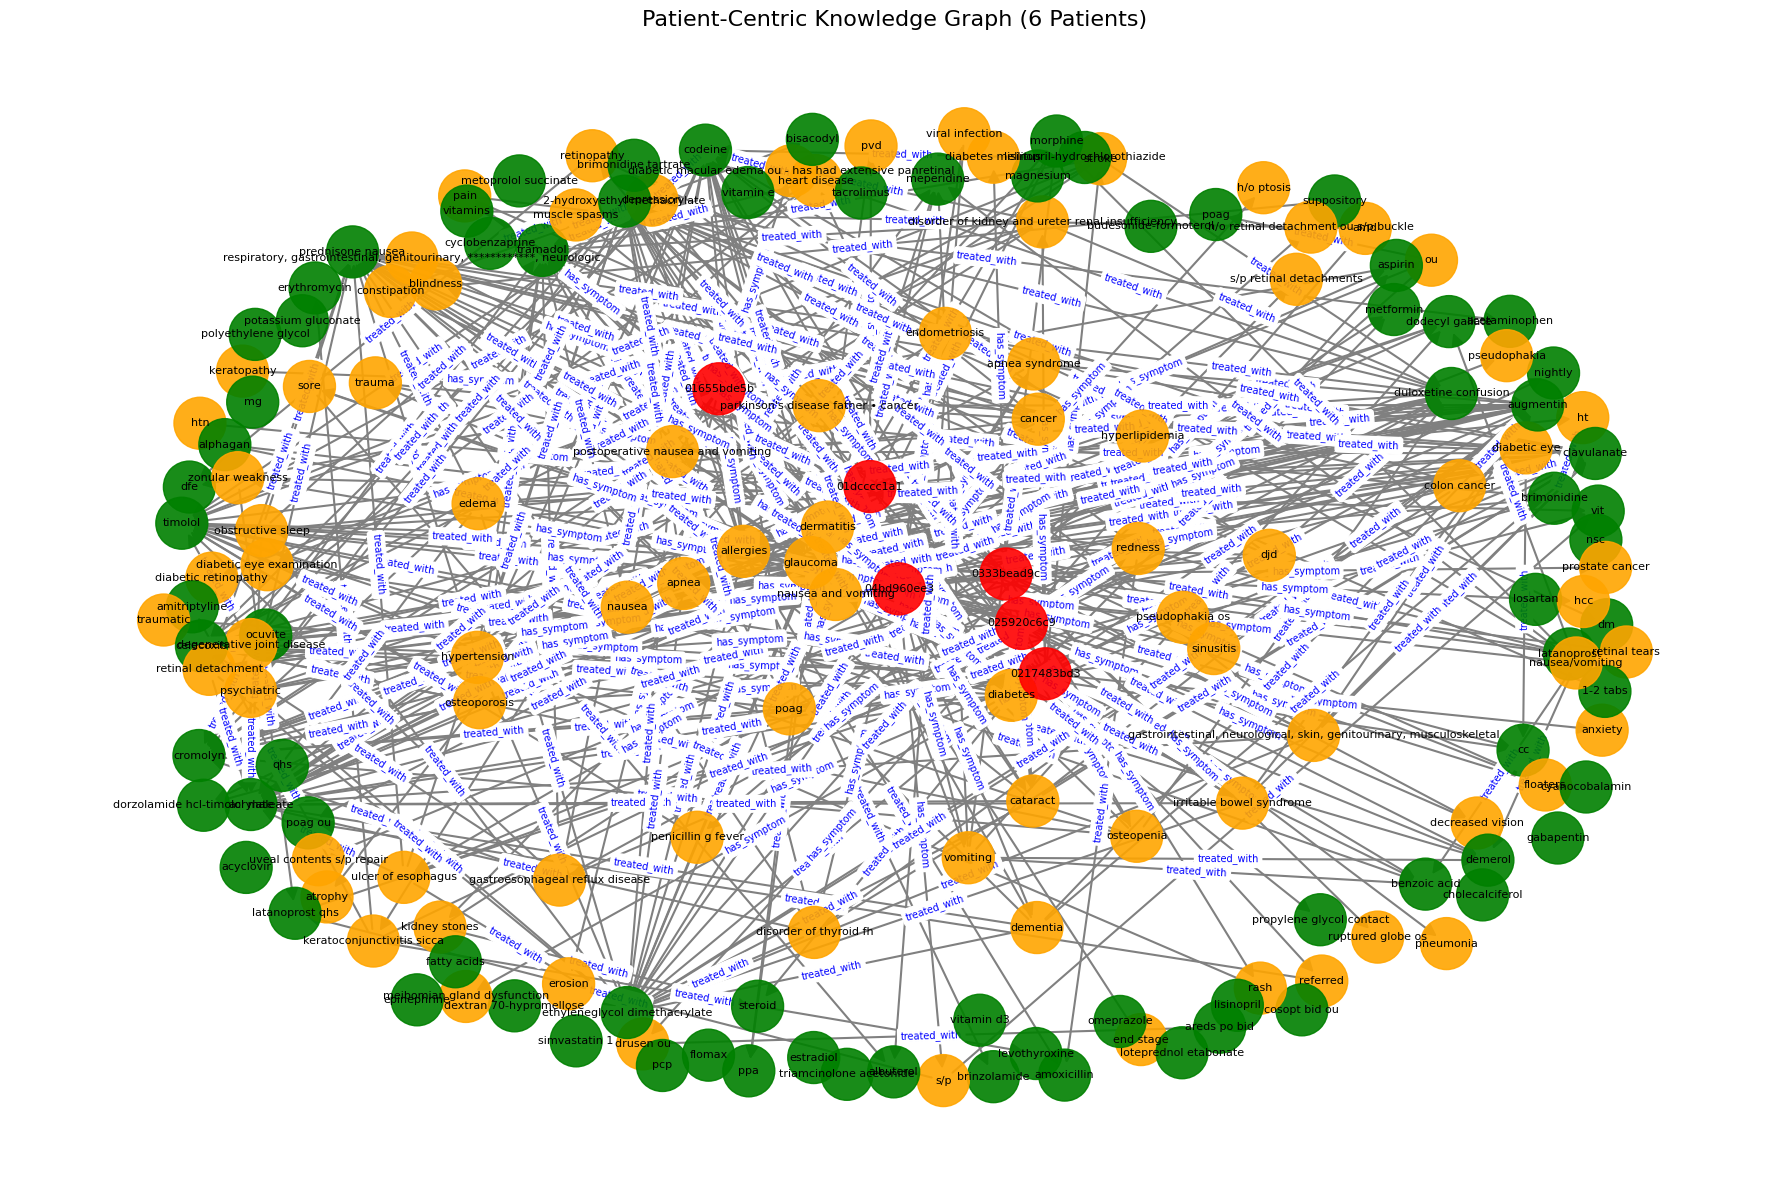

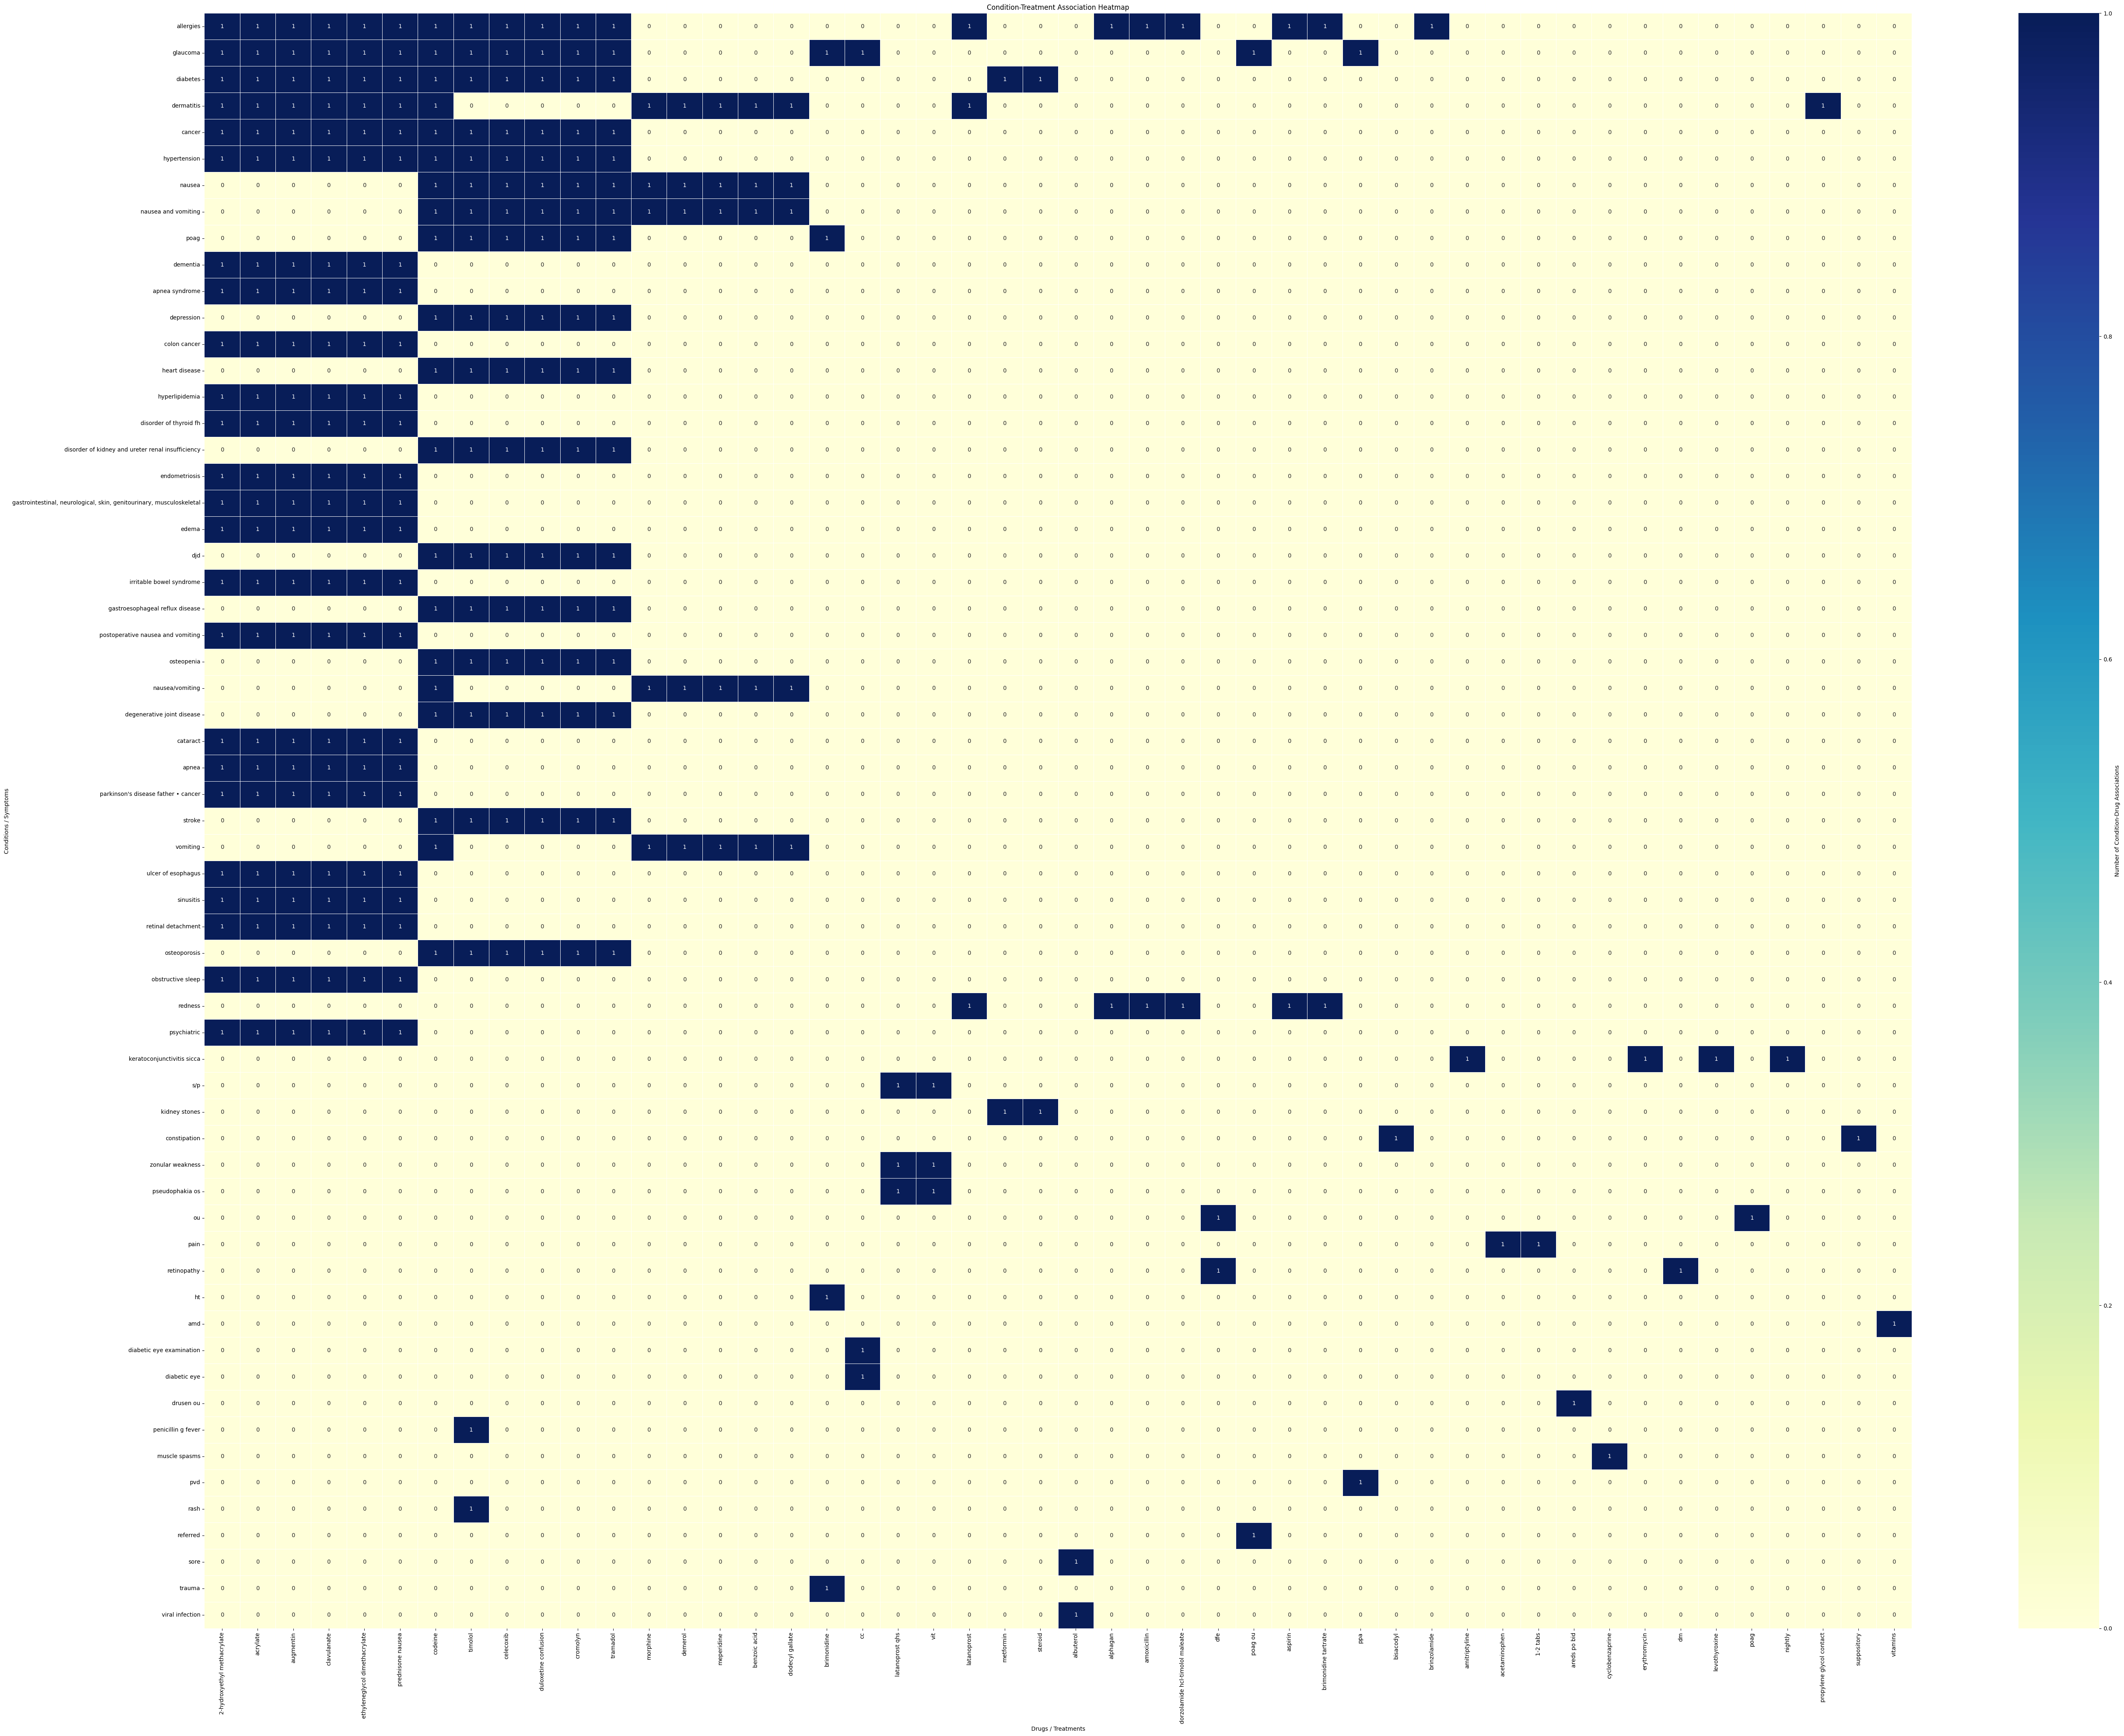


Condition-Treatment Association Table:


Drug,2-hydroxyethyl methacrylate,acrylate,augmentin,clavulanate,ethyleneglycol dimethacrylate,prednisone nausea,codeine,timolol,celecoxib,duloxetine confusion,...,areds po bid,cyclobenzaprine,erythromycin,dm,levothyroxine,poag,nightly,propylene glycol contact,suppository,vitamins
Condition,,,,,,,,,,,,,,,,,,,,,
allergies,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
glaucoma,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
diabetes,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
dermatitis,1,1,1,1,1,1,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
cancer,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
rash,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
referred,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
sore,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



GraphML file saved: output/glaucoma_patient_knowledge_graph.graphml

FILES CREATED SUCCESSFULLY
1. Patient metrics CSV:
    output/patient_metrics.csv
2. Clean combined graph PNG:
    output/combined_neat_knowledge_graph.png
3. Condition-treatment heatmap PNG:
    output/condition_treatment_heatmap.png
4. GraphML file for Gephi:
    output/glaucoma_patient_knowledge_graph.graphml
5. ZIP file containing all outputs:
    /content/glaucoma_knowledge_graph_output.zip


In [ ]:
# # ==========================================================
# # 3. PRINT COMBINED GRAPH METRICS
# # ==========================================================

print("=" * 70)
print("COMBINED KNOWLEDGE GRAPH")
print("=" * 70)

combined_metrics = calculate_graph_metrics(combined_graph)

for metric_name, metric_value in combined_metrics.items():
    print(f"{metric_name}: {metric_value}")

print("\nCombined Graph Nodes:", combined_graph.number_of_nodes())
print("Combined Graph Edges:", combined_graph.number_of_edges())


# ==========================================================
# 4. SAVE PATIENT-WISE GRAPH METRICS AS CSV
# ==========================================================

metrics_csv_file = OUTPUT_FOLDER / "patient_metrics.csv"

if "all_patient_metrics" in globals() and all_patient_metrics:
    metrics_dataframe = pd.DataFrame(all_patient_metrics)

    metrics_dataframe.to_csv(
        metrics_csv_file,
        index=False
    )

    print(f"\nPatient metrics saved: {metrics_csv_file}")

    display(metrics_dataframe)

else:
    empty_dataframe = pd.DataFrame()

    empty_dataframe.to_csv(
        metrics_csv_file,
        index=False
    )

    print("\nNo patient metrics found. Empty CSV created.")


# ==========================================================
# 5. CREATE CLEAN COMBINED KNOWLEDGE GRAPH
# ==========================================================

combined_graph_file = OUTPUT_FOLDER / "combined_neat_knowledge_graph.png"

# Fix: Replaced undefined draw_neat_knowledge_graph with defined draw_knowledge_graph
draw_knowledge_graph(
    graph=combined_graph,
    title=(
        f"Patient-Centric Knowledge Graph "
        f"({len(selected_files)} Patients)"
    ),
    save_path=combined_graph_file
)


# ==========================================================
# 6. CREATE CONDITION-TREATMENT HEATMAP
# ==========================================================

heatmap_file = OUTPUT_FOLDER / "condition_treatment_heatmap.png"

heatmap_dataframe = create_association_heatmap(
    combined_graph,
    heatmap_file
)

if heatmap_dataframe is not None:
    print("\nCondition-Treatment Association Table:")
    display(heatmap_dataframe)


# ==========================================================
# 7. EXPORT GRAPHML FILE FOR GEPHI
# ==========================================================

graphml_file = OUTPUT_FOLDER / "glaucoma_patient_knowledge_graph.graphml"

nx.write_graphml(
    combined_graph,
    graphml_file
)

print(f"\nGraphML file saved: {graphml_file}")


# ==========================================================
# 8. CREATE ZIP FILE OF ALL OUTPUTS
# ==========================================================

zip_file = shutil.make_archive(
    "glaucoma_knowledge_graph_output",
    "zip",
    OUTPUT_FOLDER
)

print("\n" + "=" * 70)
print("FILES CREATED SUCCESSFULLY")
print("=" * 70)

print("1. Patient metrics CSV:")
print("   ", metrics_csv_file)

print("2. Clean combined graph PNG:")
print("   ", combined_graph_file)

print("3. Condition-treatment heatmap PNG:")
print("   ", heatmap_file)

print("4. GraphML file for Gephi:")
print("   ", graphml_file)

print("5. ZIP file containing all outputs:")
print("   ", zip_file)